<a href="https://colab.research.google.com/github/Ziruo-261/BWSI_01_Medical_Image_Lab.ipynb/blob/main/01_Medical_Image_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 | AI Digital Pathology
**Analyze a real medical microscopy image using machine learning.**

**Goal:** train an unsupervised model to group pixels by color, then explore different tissue-staining patterns.

**Dataset:** `skimage.data.immunohistochemistry()`, a real histology image of colonic glands with hematoxylin and DAB staining, made available through scikit-image.

**Safety:** This is an educational image-analysis demonstration. Cluster colors are **not** clinical diagnoses or validated cell types. No patient information is used.

**Instructions:** Runtime → Run all. Then change `NUMBER_OF_GROUPS` and rerun the analysis cells.

### 1 | Load and inspect the medical image

Medical image shape: (512, 512, 3)


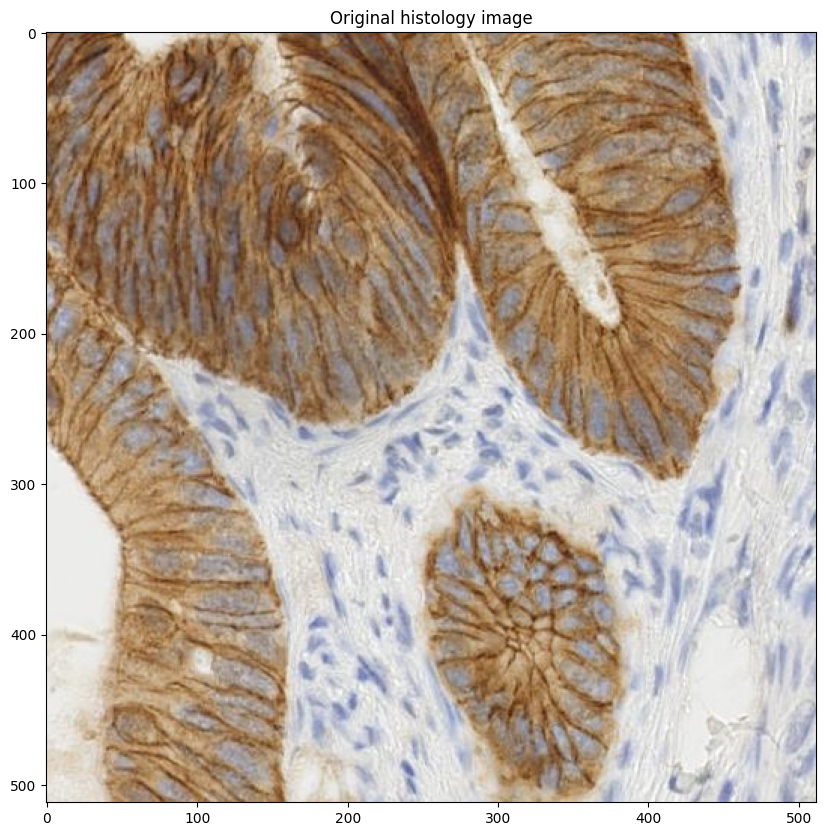

In [ ]:
# These libraries are available in a standard Google Colab Python runtime.
# We are retrieiving entire datasets and bringing it to the program.

#Numpy is for numerical caluclations
import numpy as np
# IMporting functions used to plot graphs
import matplotlib.pyplot as plt
# Importing specific data from dataset from skimage
from skimage import data, transform
from sklearn.cluster import MiniBatchKMeans

# Load a real public histology sample (not a synthetic illustration).
# Assigning variable "original" and "image"
# Pulling image from skimage data set so we can see what it looks like
original = data.immunohistochemistry()
# Creates paramaters for image such as size, shrinking the image to be presented
#anti_aliasing roughens jagged edges, makes picture look more aesthetic
image = transform.resize(original, (1000, 1000), anti_aliasing=True)
# Showing original image size ebfore being presented
print("Medical image shape:", original.shape)
# plt meanings "plotting," classifies what the image is, labeling the image
# differnet functions for how to plot the image
#dictate size of presented image
plt.figure(figsize=(10, 10))
#makes sure the image shows up
plt.imshow(original)
# Naming the graph
plt.title("Original histology image")
# Decides whether the axis is plotted
plt.axis("on")
plt.show()

### 2 | Train a model to group pixels by their color
**Machine learning idea:** K-means learns groups from examples without needing labeled training images.

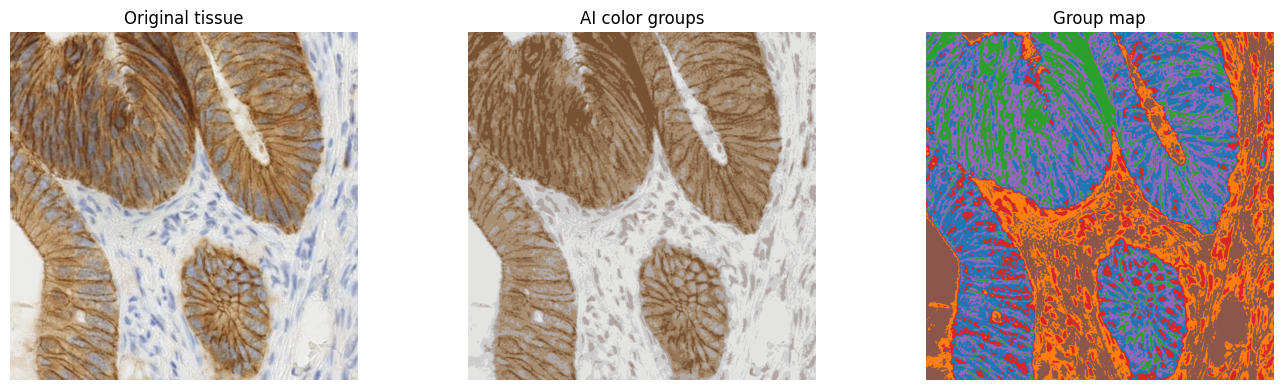

In [ ]:
# GROUP CHALLENGE: change 4 to 2, 3, 5, or 6. Compare the results.
# More colors when numbers get bigger, means more colors are able to be used
NUMBER_OF_GROUPS = 6

# A pixel contains three numbers: red, green, and blue.
# Assigning the colors to each pixel for a better image
# Each pixel utilizes three colors
pixels = image.reshape(-1, 3)
model = MiniBatchKMeans(n_clusters=NUMBER_OF_GROUPS, random_state=7,
                        n_init=3, batch_size=2048)
labels = model.fit_predict(pixels)
# Assign each pixel the average color of its learned group.
new_image = model.cluster_centers_[labels].reshape(image.shape)
label_map = labels.reshape(image.shape[:2])

# Creating the format for how all the different images are presented
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
# Labeling the axes
axes[0].imshow(image); axes[0].set_title("Original tissue")
axes[1].imshow(new_image); axes[1].set_title("AI color groups")

axes[2].imshow(label_map, cmap="tab10", vmin=0, vmax=9)
axes[2].set_title("Group map")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 3 | Measure and explain the result

Color group 0: 20.1% of image | mean RGB (np.int64(170), np.int64(144), np.int64(117))
Color group 1: 15.6% of image | mean RGB (np.int64(207), np.int64(206), np.int64(206))
Color group 2: 11.6% of image | mean RGB (np.int64(120), np.int64(84), np.int64(53))
Color group 3: 11.1% of image | mean RGB (np.int64(177), np.int64(169), np.int64(167))
Color group 4: 21.6% of image | mean RGB (np.int64(148), np.int64(116), np.int64(86))
Color group 5: 20.1% of image | mean RGB (np.int64(228), np.int64(227), np.int64(226))


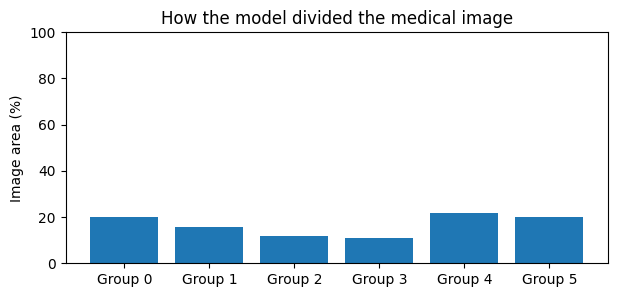

In [ ]:
# The percentage tells us how much of the image belongs to each color group.
percentages = np.bincount(labels, minlength=NUMBER_OF_GROUPS) / len(labels) * 100
for group, percent in enumerate(percentages):
    rgb = np.round(model.cluster_centers_[group] * 255).astype(int)
    print(f"Color group {group}: {percent:.1f}% of image | mean RGB {tuple(rgb)}")

# Telling how big to make the graph
plt.figure(figsize=(7, 3))
# Plotting it as a bar graph
plt.bar([f"Group {i}" for i in range(NUMBER_OF_GROUPS)], percentages)
# Labeling the axises
plt.ylabel("Image area (%)"); plt.title("How the model divided the medical image")
plt.ylim(0, 100); plt.show()

#Overall program is analyzing amount of each color to recognize patterns for medical conditions

### Team mission
1. Compare `NUMBER_OF_GROUPS = 2`, `4`, and `6`. Which result best preserves visible details?
2. Identify one region the model separates well and one it separates poorly.
3. Prepare a **30-second demonstration**: original image, AI output, and one limitation.

**Debrief:** Why is color similarity not the same as diagnosing a disease?